# Conformal prediction sets: "it's one of these"

Predict sets of classes that contain the true class 90% of the time, after training.

Instead of a single class, a **prediction set** lists every class the image could plausibly be,
chosen so that the set contains the true class **90% of the time**. Easy images get a single
class; ambiguous ones (a shirt or a T-shirt?) get several. The size of the set is an honest,
per-image measure of uncertainty.

Split conformal prediction builds these sets from any trained classifier, after training:
calibrate a threshold on held-out images, then include every class that clears it.

In [ ]:
# Install keras-proba, then choose a backend: "jax", "tensorflow" or "torch".
!pip install -q keras-proba
import os

os.environ["KERAS_BACKEND"] = "jax"

## Load the data

[Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist): 10 classes of clothing.
10,000 training images are held out for calibration.

In [2]:
import matplotlib.pyplot as plt
import numpy as np

import keras
import keras_proba

keras.utils.set_random_seed(0)
CLASSES = ["T-shirt", "trouser", "pullover", "dress", "coat", "sandal", "shirt", "sneaker", "bag", "boot"]
(x, y), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
x, x_test = x[..., None].astype("float32") / 255, x_test[..., None].astype("float32") / 255
x_cal, y_cal, x_train, y_train = x[:10_000], y[:10_000], x[10_000:], y[10_000:]

## Any trained classifier

A small CNN that outputs class probabilities.

In [3]:
model = keras.Sequential(
    [
        keras.Input((28, 28, 1)),
        keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(),
        keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(),
        keras.layers.Flatten(),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(10, activation="softmax"),
    ]
)
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(x_train, y_train, epochs=5, batch_size=128, verbose=0)
probs_cal, probs_test = model.predict(x_cal, verbose=0), model.predict(x_test, verbose=0)
print(f"Test accuracy of the most probable class: {(probs_test.argmax(-1) == y_test).mean():.1%}")

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


Test accuracy of the most probable class: 89.5%


## Calibrate and predict sets

[`SplitConformalClassifier`](https://anas-rz.github.io/keras-proba/api/postprocessing/#keras_proba.postprocessing.SplitConformalClassifier)
with `score="aps"` adds classes from the most to the least probable until their total
probability reaches a threshold calibrated on the held-out images. (`score="lac"` instead keeps
every class above a fixed probability: smaller sets on average, but less adaptive.)

In [4]:
conformal = keras_proba.postprocessing.SplitConformalClassifier(alpha=0.1, score="aps", seed=0)
conformal.fit(y_cal, probs_cal)
sets = keras.ops.convert_to_numpy(conformal.predict_set(probs_test))  # (images, classes), True = in the set.

coverage = float(keras.ops.convert_to_numpy(keras_proba.postprocessing.set_coverage(y_test, sets)))
print(f"The sets contain the true class for {coverage:.1%} of the test images, with {sets.sum(-1).mean():.2f} classes on average")

The sets contain the true class for 89.9% of the test images, with 1.23 classes on average


## What the sets look like

Clear images get one class. Ambiguous images, often tops and shirts that look alike, get
several: the set says exactly which classes the model cannot tell apart. (A few very confident
images get an empty set: that is how the APS sets hit exactly 90% on average. Count an empty set
as "probably the top class, but not guaranteed".)

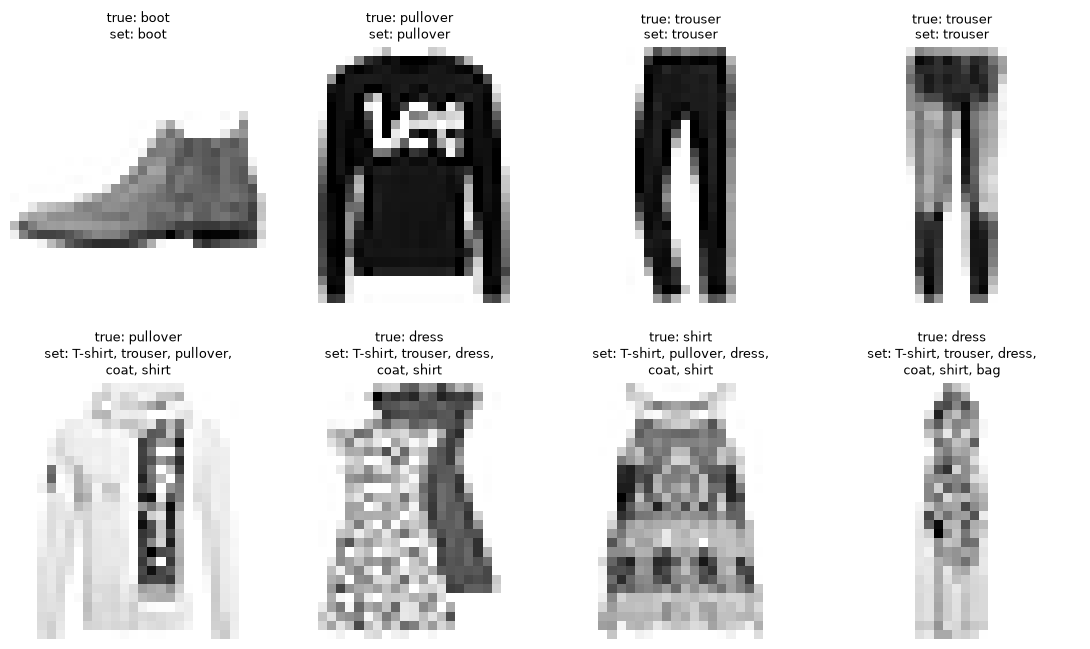

In [5]:
size = sets.sum(-1)
examples = np.concatenate([np.flatnonzero(size == 1)[:4], np.argsort(size)[-4:]])  # Four single-class sets, four of the largest.
fig, axes = plt.subplots(2, 4, figsize=(11, 7))
for ax, i in zip(axes.flat, examples):
    ax.imshow(x_test[i, ..., 0], cmap="gray_r")
    members = [CLASSES[k] for k in np.flatnonzero(sets[i])]
    lines = [", ".join(members[j : j + 3]) for j in range(0, len(members), 3)]
    ax.set_title(f"true: {CLASSES[y_test[i]]}\nset: " + ",\n".join(lines), fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Set size follows difficulty

Classes the model confuses get larger sets, and so do the images where its top prediction is
wrong: exactly where a single answer would mislead.

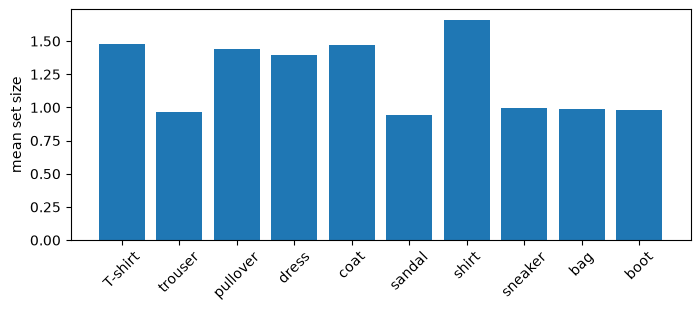

Mean set size when the top prediction is right: 1.14, when it is wrong: 2.02


In [6]:
correct = probs_test.argmax(-1) == y_test
size = sets.sum(-1)
plt.figure(figsize=(8, 3))
plt.bar(CLASSES, [size[y_test == k].mean() for k in range(10)])
plt.ylabel("mean set size")
plt.xticks(rotation=45)
plt.show()
print(f"Mean set size when the top prediction is right: {size[correct].mean():.2f}, when it is wrong: {size[~correct].mean():.2f}")

## What we learned

- Conformal prediction turns any classifier's probabilities into sets that contain the true
  class 90% of the time, after training.
- The set size is a per-image measure of uncertainty: one class for easy images, several for
  ambiguous ones.
- The guarantee assumes the calibration images resemble the test images. Here they come from the
  training set, and the official test images are slightly harder, so the coverage can land a
  little below 90%.